<a href="https://colab.research.google.com/github/zcflanzer/rcew-water-budget/blob/main/P_ETdifference_mapping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mapping difference of P and ET
Author: Zoe Flanzer\
Last edited: 5/28/2026\
Purpose: Map the difference of P - ET between wet and dry years.

In [1]:
## setting up notebook
# mounting google drive
from google.colab import drive
drive.mount('/content/drive')

# importing libraries
!pip install geopandas rioxarray netcdf4 shapely
import xarray as xr
import rioxarray
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 60.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 33.6 MB/s eta 0:00:00
  Attempting uninstall: xarray
    Found existing installation: xarray 2025.12.0
    Uninstalling xarray-2025.12.0:
      Successfully uninstalled xarray-2025.12.0


In [2]:
## importing data
nc_2006_path = "/content/drive/MyDrive/THESIS/data/Mapping/p_minus_et_2006.nc"
nc_2007_path = "/content/drive/MyDrive/THESIS/data/Mapping/p_minus_et_2007.nc"
watershed_shp_path = "/content/drive/MyDrive/THESIS/data/Shapefiles/tollgate.shp" # watershed outline

# loading data
ds_2006 = xr.open_dataset(nc_2006_path)
ds_2007 = xr.open_dataset(nc_2007_path)

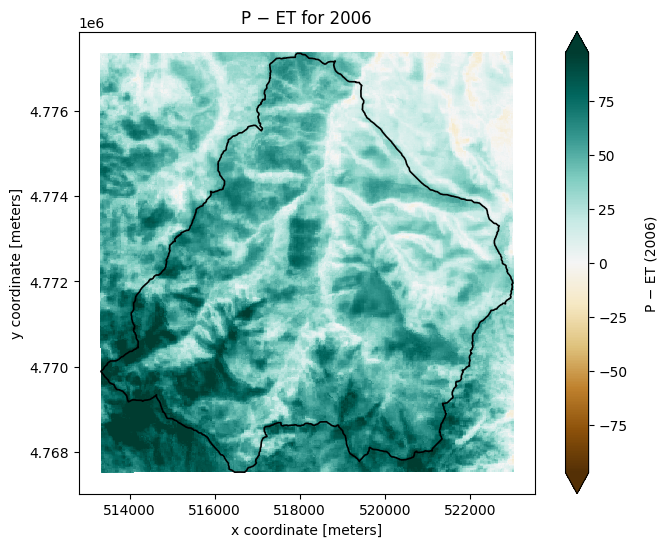

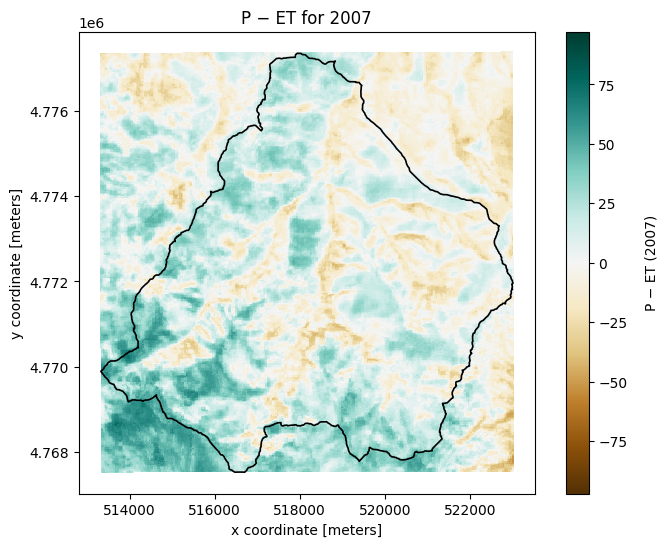

In [4]:
## mapping individual P - ET years
# extract data variable
var_2006 = list(ds_2006.data_vars)[0]
var_2007 = list(ds_2007.data_vars)[0]
r2006 = ds_2006[var_2006]
r2007 = ds_2007[var_2007]

# load catchment boundary
watershed = gpd.read_file(watershed_shp_path)
watershed = watershed.to_crs(r2006.rio.crs)

# colormap
cmap_choice = "BrBG"
norm = TwoSlopeNorm(vcenter=0) # forces 0 = white

# plotting 2006 (wet year)
fig, ax = plt.subplots(figsize=(8, 6))
mappable = r2006.plot(ax=ax,cmap=cmap_choice,norm=norm,robust=True)
watershed.boundary.plot(ax=ax, color='black', linewidth=1.2)
cbar = mappable.colorbar
cbar.set_label("P − ET (2006)", labelpad=12)
ax.set_title("P − ET for 2006")
plt.savefig('P-ET_2006.png', dpi = 300, bbox_inches='tight')
plt.show()

# plotting 2007 (dry year)
fig, ax = plt.subplots(figsize=(8, 6))
mappable = r2007.plot(ax=ax,cmap=cmap_choice,norm=norm,robust=True)
watershed.boundary.plot(ax=ax, color='black', linewidth=1.2)
cbar = mappable.colorbar
cbar.set_label("P − ET (2007)", labelpad=12)
ax.set_title("P − ET for 2007")
plt.savefig('P-ET_2007.png', dpi = 300, bbox_inches='tight')
plt.show()

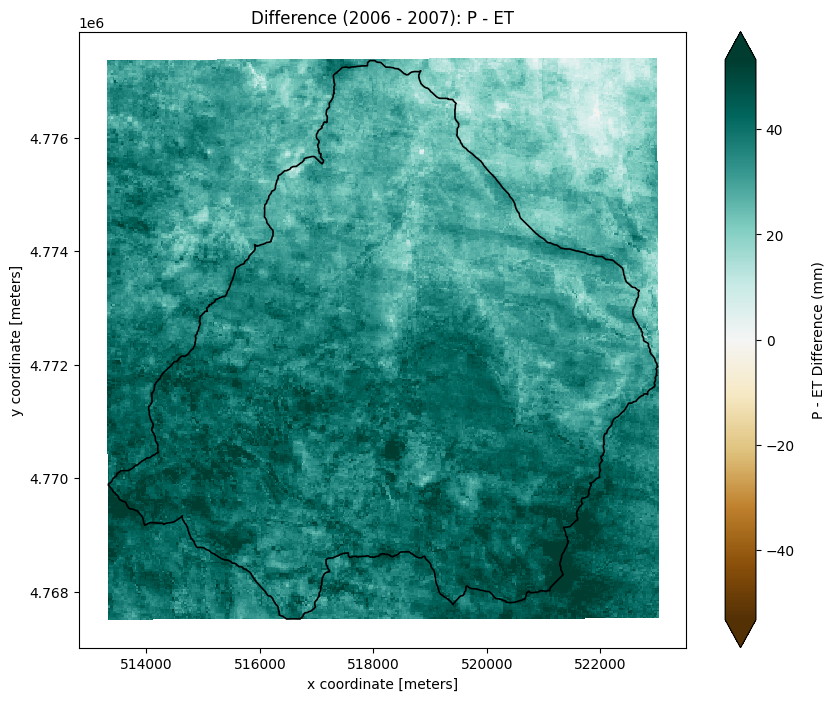

In [7]:
## mapping difference of difference
r2006 = ds_2006['__xarray_dataarray_variable__']
r2007 = ds_2007['__xarray_dataarray_variable__']

# computing difference between years (2006 - 2007)
diff = r2006 - r2007

# load watershed boundary
watershed = gpd.read_file(watershed_shp_path)
watershed = watershed.to_crs(diff.rio.crs)

# colormap
cmap_choice = "BrBG"
norm = TwoSlopeNorm(vcenter=0) # forcing 0 = white

# plotting
fig, ax = plt.subplots(figsize=(10, 8))
mappable = diff.plot(ax=ax, cmap=cmap_choice,norm=norm, robust=True)
watershed.boundary.plot(ax=ax, color='black', linewidth=1.2) # watershed boundary
cbar = mappable.colorbar
cbar.set_label('P - ET Difference (mm)', labelpad=12)
ax.set_title("Difference (2006 - 2007): P - ET")
plt.savefig('P-ET_2006-2007_difference.png', dpi = 300, bbox_inches='tight')
plt.show()